<a href="https://colab.research.google.com/github/eliseiuoi/MMA3001-smart-building-sensor-reconstruction/blob/main/02_reconstruction_validation_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconstruction of Missing Environmental Sensor Measurements

## Aim

This notebook evaluates computational methods for reconstructing missing temperature measurements from the Monash Smart Infrastructure Lab dataset.

Temperature is initially used as the target variable. Known temperature measurements are artificially removed and then reconstructed so that predicted values can be compared with the original measurements.

Linear interpolation is first evaluated as a simple numerical baseline. Machine-learning regression methods taught in MMA3001, including linear regression and decision tree regression, are then evaluated using the same validation framework.

The performance of each method will be compared using quantitative error metrics such as Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).


## Project Development Strategy

This project follows an iterative computational workflow. A simple numerical
method is first established as a baseline, after which progressively more
complex regression approaches are evaluated.

Each development step is assessed using the same withheld temperature
measurements and quantitative error metrics where possible. Results from each
experiment are used to determine the next modelling decision rather than
selecting methods based on preference alone.

The overall development flow is:

1. Audit and understand the environmental sensor data.
2. Establish linear interpolation as a numerical reconstruction baseline.
3. Evaluate linear regression using environmental predictor variables.
4. Evaluate decision tree regression as a nonlinear alternative.
5. Investigate whether additional features, including CO2 concentration and
   temporal information, improve reconstruction accuracy.
6. Evaluate sensitivity to the number and duration of consecutive missing
   temperature measurements.
7. Compare accuracy, robustness, computational cost and implementation
   complexity before selecting the final recommended approach.

# 1. Data Preparation:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv")

df["time"] = pd.to_datetime(df["time"])

df = df.sort_values("time").reset_index(drop=True)

display(df.head())

,time,Pressure (mb),Temperature (°C),Humidity (RH %),CO2 (ppm),LVOC (ppb),Formaldehyde (µg/m3)
0,2025-07-30 10:39:23,1012,24.8,32,612.0,0,4.0
1,2025-07-30 10:46:38,1012,24.8,32,630.0,0,NaN
2,2025-07-30 11:01:12,1012,24.8,32,626.0,0,4.0
3,2025-07-30 11:05:57,1012,24.8,32,624.0,0,4.0
4,2025-07-30 11:39:22,1012,25.0,31,584.0,0,4.0


In [ ]:
#Extract only temparature:
temperature_data = df[["time", "Temperature (°C)"]].copy()

display(temperature_data.head())

,time,Temperature (°C)
0,2025-07-30 10:39:23,24.8
1,2025-07-30 10:46:38,24.8
2,2025-07-30 11:01:12,24.8
3,2025-07-30 11:05:57,24.8
4,2025-07-30 11:39:22,25.0


In [ ]:

#Check whether temparature itself contains missing measurements:

print(temperature_data.isna().sum())


#Check duplicate timestamps:
print(
    "Duplicate timestamps:",
    temperature_data["time"].duplicated().sum()
)

time                0
Temperature (°C)    0
dtype: int64
Duplicate timestamps: 0


# 2. Baseline Method: Linear Interpolation

## 2.1 Single-Point Demonstration

In [ ]:
#Select one real measurement:

#find approximately the middle measurement.
test_index = len(temperature_data) // 2


#We're choosing a point from the middle rather than the beginning or end because linear interpolation needs measurements before and after the missing point.

temperature_data.loc[
    test_index - 2:test_index + 2
]



,time,Temperature (°C)
2478,2025-09-16 14:12:04,24.8
2479,2025-09-16 14:21:51,24.5
2480,2025-09-16 14:36:59,24.3
2481,2025-09-16 14:42:12,24.0
2482,2025-09-16 14:51:34,24.3


In [ ]:
#Store the actual value:
actual_temperature = temperature_data.loc[
    test_index,
    "Temperature (°C)"
]

test_time = temperature_data.loc[
    test_index,
    "time"
]

print("Test time:", test_time)
print("Actual temperature:", actual_temperature, "°C")


Test time: 2025-09-16 14:36:59
Actual temperature: 24.3 °C


In [ ]:
#Artificially remove it:

#Make a copy:
test_data = temperature_data.copy()

#Remove the measurement:
test_data.loc[
    test_index,
    "Temperature (°C)"
] = np.nan


#Display the area around it:
display(
    test_data.loc[test_index - 2:test_index + 2]
)


,time,Temperature (°C)
2478,2025-09-16 14:12:04,24.8
2479,2025-09-16 14:21:51,24.5
2480,2025-09-16 14:36:59,NaN
2481,2025-09-16 14:42:12,24.0
2482,2025-09-16 14:51:34,24.3


In [ ]:
#Do linear interpolation manually:

t1 = temperature_data.loc[test_index - 1, "time"]
T1 = temperature_data.loc[test_index - 1, "Temperature (°C)"]

t = temperature_data.loc[test_index, "time"]

t2 = temperature_data.loc[test_index + 1, "time"]
T2 = temperature_data.loc[test_index + 1, "Temperature (°C)"]

print("Previous:", t1, T1)
print("Missing point time:", t)
print("Next:", t2, T2)

Previous: 2025-09-16 14:21:51 24.5
Missing point time: 2025-09-16 14:36:59
Next: 2025-09-16 14:42:12 24.0


In [ ]:
predicted_temperature = T1 + (
    (t - t1) / (t2 - t1)
) * (T2 - T1)

print(
    "Predicted temperature:",
    predicted_temperature,
    "°C"
)

print(
    "Actual temperature:",
    actual_temperature,
    "°C"
)

Predicted temperature: 24.128173628173627 °C
Actual temperature: 24.3 °C


In [ ]:
#Calculate the error:

absolute_error = abs(
    actual_temperature - predicted_temperature
)

print(
    "Absolute error:",
    absolute_error,
    "°C"
)


Absolute error: 0.1718263718263735 °C


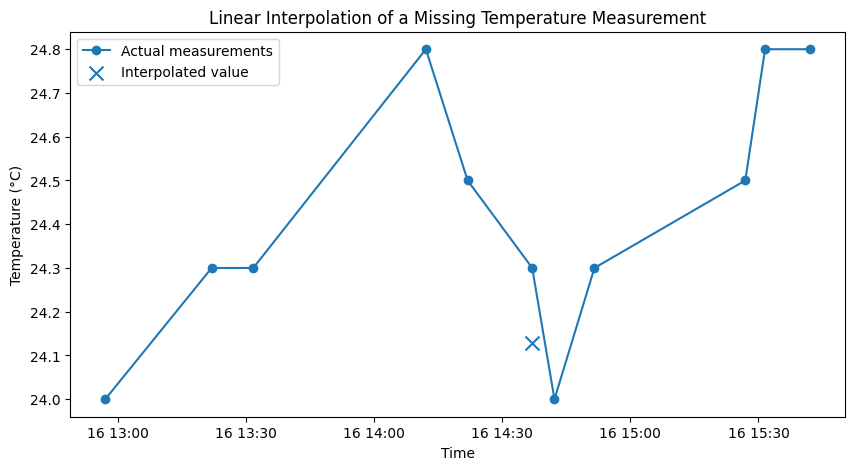

In [ ]:
#Visualise what happened:
plot_data = temperature_data.loc[
    test_index - 5:test_index + 5
]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["time"],
    plot_data["Temperature (°C)"],
    marker="o",
    label="Actual measurements"
)

plt.scatter(
    test_time,
    predicted_temperature,
    marker="x",
    s=100,
    label="Interpolated value"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Linear Interpolation of a Missing Temperature Measurement")
plt.legend()

plt.show()

## Initial Linear Interpolation Test

A known temperature measurement was artificially removed from the dataset
to simulate a sensor measurement failure.

Linear interpolation was then used to reconstruct the missing measurement
using the measurements immediately before and after the removed point.

Because the original value was known, the reconstructed value could be
directly compared with the true measurement. This provides a simple
validation of the interpolation method.

Now repeat the experiment many times. Instead of hiding one value, we'll hide many known values and see how the method performs overall.

Choose every 20th measurement, while avoiding the beginning and end.

## 2.2 Multi-Point Validation:

In [ ]:
validation_indices = np.arange(
    10,
    len(temperature_data) - 10,
    20
)

print(
    "Number of validation points:",
    len(validation_indices)
)

Number of validation points: 247


In [ ]:
#Hide all those values:
validation_data = temperature_data.copy()

actual_values = validation_data.loc[
    validation_indices,
    "Temperature (°C)"
].copy()

validation_data.loc[
    validation_indices,
    "Temperature (°C)"
] = np.nan

In [ ]:
#Let pandas perform time-based interpolation:
validation_data = validation_data.set_index("time")

validation_times = temperature_data.loc[
    validation_indices,
    "time"
]

validation_data["linear_interpolated"] = (
    validation_data["Temperature (°C)"]
    .interpolate(method="time")
)

display(
    validation_data.loc[
        validation_times,
        ["Temperature (°C)", "linear_interpolated"]
    ].head()
)

,Temperature (°C),linear_interpolated
time,,
2025-07-30 14:56:33,NaN,25.654945
2025-07-30 20:29:08,NaN,24.672085
2025-07-31 01:16:05,NaN,23.800000
2025-07-31 10:04:09,NaN,23.855658
2025-07-31 14:16:51,NaN,24.000000


In [ ]:
#Extract predictions:
validation_times = temperature_data.loc[
    validation_indices,
    "time"
]

predicted_values = validation_data.loc[
    validation_times,
    "linear_interpolated"
].to_numpy()

actual_values = actual_values.to_numpy()

## 2.3 Baseline Results:

In [ ]:
#Calcualte MAE and RMSE:

mae = np.mean(
    np.abs(actual_values - predicted_values)
)

rmse = np.sqrt(
    np.mean(
        (actual_values - predicted_values) ** 2
    )
)

print("MAE:", mae, "°C")
print("RMSE:", rmse, "°C")

MAE: 0.12425081632736212 °C
RMSE: 0.2214190921287753 °C


## Linear Interpolation Baseline Results

Linear interpolation achieved an MAE of approximately 0.124 °C and an RMSE
of approximately 0.221 °C when reconstructing artificially removed
temperature measurements.

The RMSE is higher than the MAE, indicating that some reconstructed
measurements have larger errors than the typical prediction error.

These results establish a numerical baseline for comparison with
machine-learning regression methods evaluated using the same withheld
temperature measurements.

# 3. Machine-Learning Regression Methods

The next stage investigates whether regression models can reconstruct missing
temperature measurements using other environmental sensor variables.

The same withheld temperature measurements used to evaluate linear
interpolation will be retained for the regression models. This allows the
methods to be compared using the same ground-truth measurements and the same
error metrics.

The first machine-learning model evaluated is linear regression, followed by
decision tree regression.

### Assumption

This analysis assumes that the temperature measurement is missing while other
environmental variables remain available. Therefore, it represents a missing
temperature channel or corrupted temperature measurement rather than a
complete environmental sensor outage.

## 3.1.  Feature and Target Definition (*X* and *y*):
Temperature is selected as the regression target.

The initial linear regression model uses pressure and humidity as predictor
features. These variables are available throughout the dataset and provide a
simple starting model before investigating additional features.

- **Features (X):** Pressure and Humidity
- **Target (y):** Temperature

In [ ]:
# Define predictor features and target variable

features = [
    "Pressure (mb)",
    "Humidity (RH %)"
]

target = "Temperature (°C)"

X = df[features].copy()
y = df[target].copy()

display(X.head())
display(y.head())

,Pressure (mb),Humidity (RH %)
0,1012,32
1,1012,32
2,1012,32
3,1012,32
4,1012,31


,Temperature (°C)
0,24.8
1,24.8
2,24.8
3,24.8
4,25.0


## 3.2 Use the SAME validation points

In [ ]:
# Use the same validation points as the interpolation experiment

validation_mask = df.index.isin(validation_indices)

X_train = X.loc[~validation_mask] #mean NOT validation_mask, flips every Boolean
y_train = y.loc[~validation_mask]

X_validation = X.loc[validation_mask]
y_validation = y.loc[validation_mask]
# We're not literally replacing the validation temparature with NaN this time.
# Instead, we simply exclude them from model training (y_validation) only
# because we need the true temparatures later to assess the prediction.


print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))

Training samples: 4713
Validation samples: 247


## 3.3 Check the split


In [ ]:
print("Total measurements:", len(df))

print(
    "Training + validation:",
    len(X_train) + len(X_validation)
)

display(X_validation.head())
display(y_validation.head())

Total measurements: 4960
Training + validation: 4960


,Pressure (mb),Humidity (RH %)
10,1012,32
30,1015,33
50,1017,32
70,1020,33
90,1018,33


,Temperature (°C)
10,25.5
30,24.5
50,23.8
70,23.5
90,23.8


## 3.4 Train Linear Regression:  


In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
linear_regression_model = LinearRegression()

linear_regression_model.fit(
    X_train,
    y_train
)

LinearRegression()

## 3.5 Look at what the model learned

In [ ]:
print(
    "Intercept:",
    linear_regression_model.intercept_
)

coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_regression_model.coef_
})

display(coefficient_table)

Intercept: 42.04542510272555


,Feature,Coefficient
0,Pressure (mb),-0.016545
1,Humidity (RH %),-0.018444


## 3.6 Predict the hidden temparatures:  


In [ ]:
linear_regression_predictions = (
    linear_regression_model.predict(X_validation)
)

In [ ]:
# Create a table:

linear_regression_results = pd.DataFrame({
    "Actual Temperature (°C)": y_validation.to_numpy(),
    "Predicted Temperature (°C)": linear_regression_predictions
})

display(linear_regression_results.head(10))

,Actual Temperature (°C),Predicted Temperature (°C)
0,25.5,24.711895
1,24.5,24.643817
2,23.8,24.629171
3,23.5,24.561093
4,23.8,24.594182
5,24.0,24.540750
6,24.3,24.577637
7,24.0,24.577637
8,25.3,24.542649
9,24.0,24.540750


## 3.7 Calculate MAE and RMSE

In [ ]:
linear_regression_mae = np.mean(
    np.abs(
        y_validation.to_numpy()
        - linear_regression_predictions
    )
)

linear_regression_rmse = np.sqrt(
    np.mean(
        (
            y_validation.to_numpy()
            - linear_regression_predictions
        ) ** 2
    )
)

print(
    "Linear Regression MAE:",
    linear_regression_mae,
    "°C"
)

print(
    "Linear Regression RMSE:",
    linear_regression_rmse,
    "°C"
)

Linear Regression MAE: 0.6920958353390523 °C
Linear Regression RMSE: 0.844096538778313 °C


## 3.8 Make the first method comparison table

In [ ]:
method_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse
    ]
})

display(method_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097


## 3.9 Calculate residuals:





In [ ]:
linear_regression_residuals = (
    y_validation.to_numpy()
    - linear_regression_predictions
)

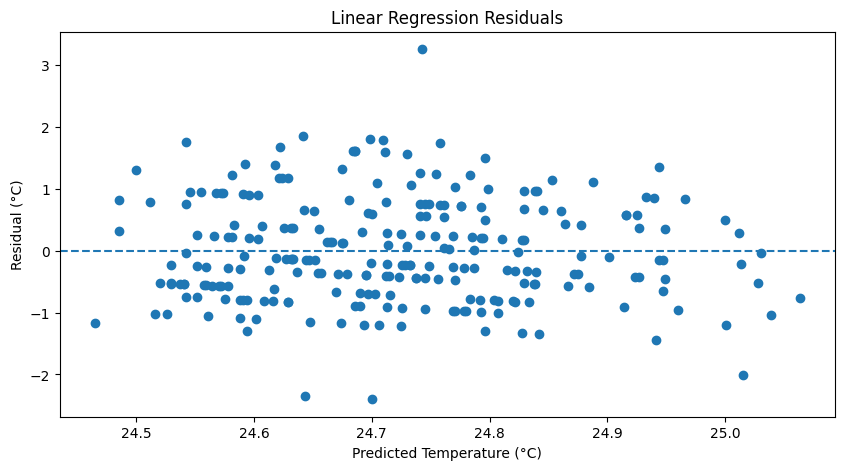

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    linear_regression_predictions,
    linear_regression_residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Linear Regression Residuals")

plt.show()

### Initial Method Comparison

Linear interpolation achieved substantially lower reconstruction errors than
the initial linear regression model.

- Linear interpolation: MAE = 0.124 °C, RMSE = 0.221 °C
- Linear regression: MAE = 0.692 °C, RMSE = 0.844 °C

The linear regression model used pressure and humidity as predictor features,
whereas linear interpolation used neighbouring temperature measurements and
their timestamps.

The poorer performance of linear regression suggests that pressure and
humidity alone do not provide sufficient information for a simple linear
model to accurately reconstruct temperature. The residual plot also shows
several relatively large prediction errors.

These results do not establish that regression methods are unsuitable in
general. A more flexible nonlinear regression model will next be evaluated
using the same predictor features and validation points.



# 4. Decision Tree Regression

Decision tree regression is evaluated as a nonlinear alternative to linear
regression.

The model uses the same predictor features and validation points as the
linear regression model:

- Pressure
- Humidity

The target remains temperature.

Unlike linear regression, a decision tree can learn nonlinear relationships
by repeatedly splitting the feature space using threshold rules.


In [ ]:
from sklearn.tree import DecisionTreeRegressor

## 4.1 Create an initial tree

In [ ]:
decision_tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

## 4.2 Train it

In [ ]:
decision_tree_model.fit(
    X_train,
    y_train
)

DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)

## 4.3 Predict the validation temperatures

In [ ]:
decision_tree_predictions = (
    decision_tree_model.predict(X_validation)
)

In [ ]:
#Inspect some predictions:

decision_tree_results = pd.DataFrame({
    "Actual Temperature (°C)": y_validation.to_numpy(),
    "Predicted Temperature (°C)": decision_tree_predictions
})

display(decision_tree_results.head(10))

,Actual Temperature (°C),Predicted Temperature (°C)
0,25.5,24.524906
1,24.5,24.746014
2,23.8,24.746014
3,23.5,24.555390
4,23.8,24.555390
5,24.0,24.248421
6,24.3,24.555390
7,24.0,24.555390
8,25.3,24.248421
9,24.0,24.248421


## 4.4 Calculate MAE and RMSE

In [ ]:
decision_tree_mae = np.mean(
    np.abs(
        y_validation.to_numpy()
        - decision_tree_predictions
    )
)

decision_tree_rmse = np.sqrt(
    np.mean(
        (
            y_validation.to_numpy()
            - decision_tree_predictions
        ) ** 2
    )
)

print(
    "Decision Tree MAE:",
    decision_tree_mae,
    "°C"
)

print(
    "Decision Tree RMSE:",
    decision_tree_rmse,
    "°C"
)

Decision Tree MAE: 0.6807796486562573 °C
Decision Tree RMSE: 0.838483252425696 °C


## 4.5 Update your comparision table

In [ ]:
method_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Decision Tree Regression"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        decision_tree_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        decision_tree_rmse
    ]
})

display(method_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Decision Tree Regression,0.680780,0.838483


## 4.6 Visualise the tree:

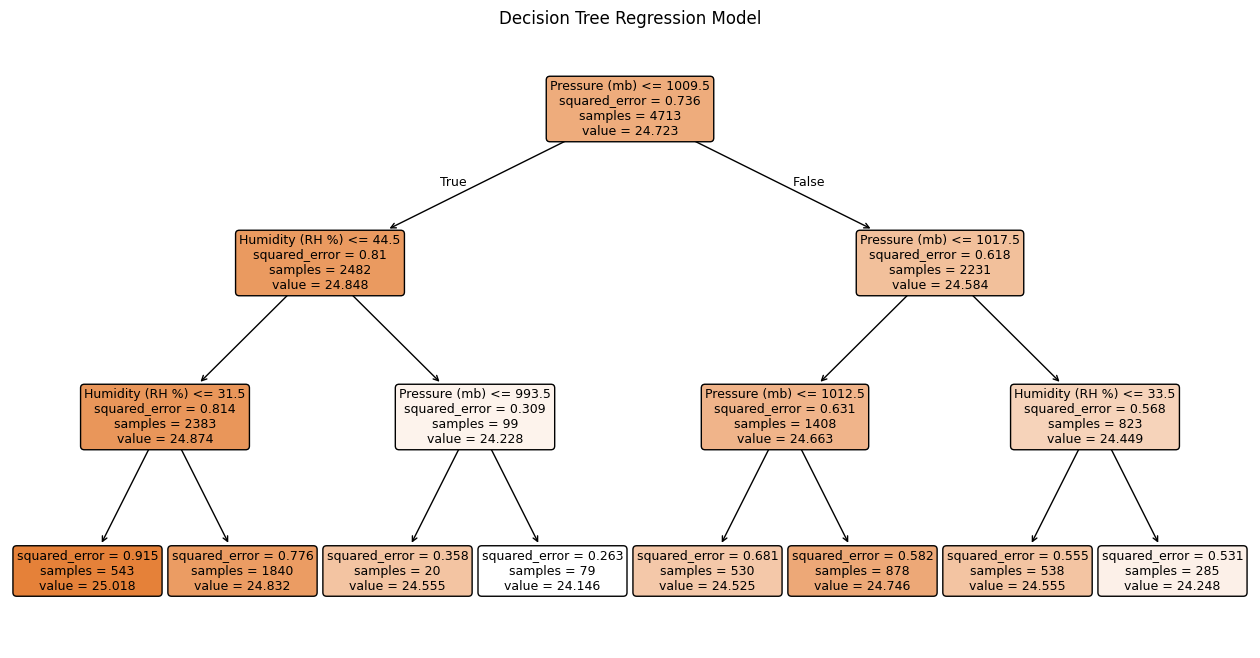

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    decision_tree_model,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Regression Model")

plt.show()

## 4.7 Residual plot

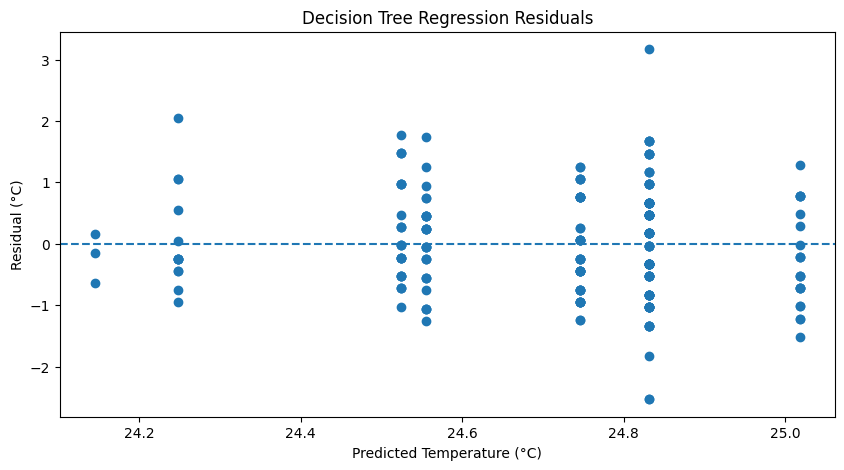

In [ ]:
decision_tree_residuals = (
    y_validation.to_numpy()
    - decision_tree_predictions
)

plt.figure(figsize=(10, 5))

plt.scatter(
    decision_tree_predictions,
    decision_tree_residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Decision Tree Regression Residuals")

plt.show()

### Initial Decision Tree Results

Decision tree regression produced an MAE of approximately 0.681 °C and an
RMSE of approximately 0.838 °C.

This represents only a small improvement over the initial linear regression
model, which achieved an MAE of 0.692 °C and an RMSE of 0.844 °C.

Although the decision tree can represent nonlinear relationships between
pressure, humidity and temperature, the improvement is limited. This suggests
that model flexibility alone is not sufficient and that pressure and humidity
may not contain enough information to accurately reconstruct temperature.

The vertical groups visible in the residual plot occur because a decision tree
produces piecewise-constant predictions. Observations falling within the same
terminal leaf receive the same predicted temperature.

Linear interpolation remains substantially more accurate under the current
validation conditions.

# 5. Feature Expansion: Adding CO₂


The initial regression models used pressure and humidity to predict temperature.
Both linear regression and decision tree regression performed substantially
worse than the linear interpolation baseline.

The next experiment investigates whether adding CO₂ concentration provides
additional information that improves temperature reconstruction.

The model structure, validation points and evaluation metrics are kept
consistent so that the effect of adding CO₂ can be assessed.

In [ ]:
#Define the new feature set:
features_co2 = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)"
]

X_co2 = df[features_co2].copy()
y_co2 = df["Temperature (°C)"].copy()

In [ ]:
# Check number of missing readings:
print(X_co2.isna().sum())

Pressure (mb)      0
Humidity (RH %)    0
CO2 (ppm)          2
dtype: int64


In [ ]:
# Check whether any of the validation points have missing CO2:
validation_mask = df.index.isin(validation_indices)

print(
    "Validation rows with missing features:",
    X_co2.loc[validation_mask].isna().any(axis=1).sum()
)

Validation rows with missing features: 0


In [ ]:
# Remove training rows with missing feature values
training_mask_co2 = (~validation_mask) & X_co2.notna().all(axis=1)

X_train_co2 = X_co2.loc[training_mask_co2]
y_train_co2 = y_co2.loc[training_mask_co2]

# Keep exactly the same validation points
X_validation_co2 = X_co2.loc[validation_mask]
y_validation_co2 = y_co2.loc[validation_mask]

print("Training samples:", len(X_train_co2))
print("Validation samples:", len(X_validation_co2))

Training samples: 4711
Validation samples: 247


In [ ]:
# Retrain Linear Regression:

linear_regression_co2 = LinearRegression()

linear_regression_co2.fit(
    X_train_co2,
    y_train_co2
)

linear_regression_co2_predictions = (
    linear_regression_co2.predict(X_validation_co2)
)

In [ ]:
# Calculate its errors:

linear_regression_co2_mae = np.mean(
    np.abs(
        y_validation_co2.to_numpy()
        - linear_regression_co2_predictions
    )
)

linear_regression_co2_rmse = np.sqrt(
    np.mean(
        (
            y_validation_co2.to_numpy()
            - linear_regression_co2_predictions
        ) ** 2
    )
)

print("Linear Regression + CO2 MAE:",
      linear_regression_co2_mae, "°C")

print("Linear Regression + CO2 RMSE:",
      linear_regression_co2_rmse, "°C")


Linear Regression + CO2 MAE: 0.6747935145467142 °C
Linear Regression + CO2 RMSE: 0.8351675072912422 °C


In [ ]:
# Repeat for the Decision Tree:

decision_tree_co2 = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

decision_tree_co2.fit(
    X_train_co2,
    y_train_co2
)

decision_tree_co2_predictions = (
    decision_tree_co2.predict(X_validation_co2)
)

In [ ]:
# Calculate its errors:

decision_tree_co2_mae = np.mean(
    np.abs(
        y_validation_co2.to_numpy()
        - decision_tree_co2_predictions
    )
)

decision_tree_co2_rmse = np.sqrt(
    np.mean(
        (
            y_validation_co2.to_numpy()
            - decision_tree_co2_predictions
        ) ** 2
    )
)

print("Decision Tree + CO2 MAE:",
      decision_tree_co2_mae, "°C")

print("Decision Tree + CO2 RMSE:",
      decision_tree_co2_rmse, "°C")

Decision Tree + CO2 MAE: 0.5922337439645724 °C
Decision Tree + CO2 RMSE: 0.76486490624837 °C


In [ ]:
# Comparision table:

feature_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Linear Regression + CO2",
        "Decision Tree Regression",
        "Decision Tree Regression + CO2"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        linear_regression_co2_mae,
        decision_tree_mae,
        decision_tree_co2_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        linear_regression_co2_rmse,
        decision_tree_rmse,
        decision_tree_co2_rmse
    ]
})

display(feature_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Linear Regression + CO2,0.674794,0.835168
3,Decision Tree Regression,0.680780,0.838483
4,Decision Tree Regression + CO2,0.592234,0.764865


### Effect of Adding CO₂

Adding CO₂ concentration produced a small improvement in the linear regression
model and a more noticeable improvement in the decision tree regression model.

Linear regression improved from an MAE of 0.692 °C to 0.675 °C, while the
decision tree improved from an MAE of 0.681 °C to 0.592 °C.

This suggests that CO₂ contains additional information relevant to temperature
reconstruction, particularly when nonlinear relationships can be represented.

However, linear interpolation remains substantially more accurate than both
regression approaches under the current validation conditions.

# 6. Feature Expansion: Temporal Information

Temperature may vary systematically with time due to daily building operation,
HVAC behaviour, occupancy and environmental conditions.

The next experiment therefore introduces temporal features in addition to
pressure, humidity and CO₂.

Hour-of-day information is represented using cyclical sine and cosine features
so that times near midnight remain close to one another numerically.

In [ ]:
# Extract hour as a decimal value

df["hour_decimal"] = (
    df["time"].dt.hour
    + df["time"].dt.minute / 60
    + df["time"].dt.second / 3600
)

In [ ]:
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour_decimal"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour_decimal"] / 24
)

# make 23:00 and 00:00 close together

In [ ]:
features_time = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)",
    "hour_sin",
    "hour_cos"
]

X_time = df[features_time].copy()

y_time = df["Temperature (°C)"].copy()

In [ ]:
# check missing values:

print(X_time.isna().sum())

Pressure (mb)      0
Humidity (RH %)    0
CO2 (ppm)          2
hour_sin           0
hour_cos           0
dtype: int64


In [ ]:
# check validation rule:

validation_mask = df.index.isin(validation_indices)

print(
    "Validation rows with missing features:",
    X_time.loc[validation_mask].isna().any(axis=1).sum()
)


Validation rows with missing features: 0


In [ ]:
training_mask_time = (
    (~validation_mask)
    & X_time.notna().all(axis=1)
)

X_train_time = X_time.loc[training_mask_time]
y_train_time = y_time.loc[training_mask_time]

X_validation_time = X_time.loc[validation_mask]
y_validation_time = y_time.loc[validation_mask]

print("Training samples:", len(X_train_time))
print("Validation samples:", len(X_validation_time))

Training samples: 4711
Validation samples: 247


In [ ]:
# Retrain Linear Regression:

linear_regression_time = LinearRegression()

linear_regression_time.fit(
    X_train_time,
    y_train_time
)

linear_regression_time_predictions = (
    linear_regression_time.predict(
        X_validation_time
    )
)

In [ ]:
# Calculate errors:

linear_regression_time_mae = np.mean(
    np.abs(
        y_validation_time.to_numpy()
        - linear_regression_time_predictions
    )
)

linear_regression_time_rmse = np.sqrt(
    np.mean(
        (
            y_validation_time.to_numpy()
            - linear_regression_time_predictions
        ) ** 2
    )
)

print(
    "Linear Regression + CO2 + Time MAE:",
    linear_regression_time_mae
)


print(
    "Linear Regression + CO2 + Time RMSE:",
    linear_regression_time_rmse
)

Linear Regression + CO2 + Time MAE: 0.6128791598177458
Linear Regression + CO2 + Time RMSE: 0.7786607585674965


In [ ]:
# Do the same for Decision Tree:

decision_tree_time = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

decision_tree_time.fit(
    X_train_time,
    y_train_time
)

decision_tree_time_predictions = (
    decision_tree_time.predict(
        X_validation_time
    )
)

In [ ]:
decision_tree_time_mae = np.mean(
    np.abs(
        y_validation_time.to_numpy()
        - decision_tree_time_predictions
    )
)

decision_tree_time_rmse = np.sqrt(
    np.mean(
        (
            y_validation_time.to_numpy()
            - decision_tree_time_predictions
        ) ** 2
    )
)

print(
    "Decision Tree + CO2 + Time MAE:",
    decision_tree_time_mae
)

print(
    "Decision Tree + CO2 + Time RMSE:",
    decision_tree_time_rmse
)

Decision Tree + CO2 + Time MAE: 0.5765998435013115
Decision Tree + CO2 + Time RMSE: 0.742592941182237


In [ ]:
# Update the table:
time_feature_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Linear Regression + CO2",
        "Linear Regression + CO2 + Time",
        "Decision Tree",
        "Decision Tree + CO2",
        "Decision Tree + CO2 + Time"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        linear_regression_co2_mae,
        linear_regression_time_mae,
        decision_tree_mae,
        decision_tree_co2_mae,
        decision_tree_time_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        linear_regression_co2_rmse,
        linear_regression_time_rmse,
        decision_tree_rmse,
        decision_tree_co2_rmse,
        decision_tree_time_rmse
    ]
})

display(time_feature_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Linear Regression + CO2,0.674794,0.835168
3,Linear Regression + CO2 + Time,0.612879,0.778661
4,Decision Tree,0.680780,0.838483
5,Decision Tree + CO2,0.592234,0.764865
6,Decision Tree + CO2 + Time,0.576600,0.742593
